In [5]:

!pip -q install gradio

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gradio as gr

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:

# Load the Titanic dataset

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

print("Titanic dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Titanic dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:

print("DATASET OVERVIEW")
print("=" * 40)

print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nStatistical summary:")
display(df.describe(include="all").transpose())

print("\nSurvival counts:")
display(df["Survived"].value_counts().rename({
    0: "Did not survive",
    1: "Survived"
}))

DATASET OVERVIEW
Rows and columns: (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Missing values:


,Missing Values
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0



Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Dooley, Mr. Patrick",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292



Survival counts:


,count
Survived,
Did not survive,549
Survived,342


In [8]:

# Select useful passenger features

features = [
    "Pclass", "Sex", "Age", "SibSp",
    "Parch", "Fare", "Embarked"
]

X = df[features].copy()
y = df["Survived"].copy()

numeric_features = [
    "Pclass", "Age", "SibSp", "Parch", "Fare"
]

categorical_features = ["Sex", "Embarked"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Features prepared successfully!")
print("Missing values will be handled inside the model pipeline.")

Features prepared successfully!
Missing values will be handled inside the model pipeline.


In [9]:

# TRAIN THE TITANIC SURVIVAL MODEL

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

titanic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

titanic_model.fit(X_train, y_train)

y_pred = titanic_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("MODEL TRAINED SUCCESSFULLY!")
print("-" * 40)
print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1 Score:  {f1:.3f}")

MODEL TRAINED SUCCESSFULLY!
----------------------------------------
Accuracy:  80.45%
Precision: 0.793
Recall:    0.667
F1 Score:  0.724


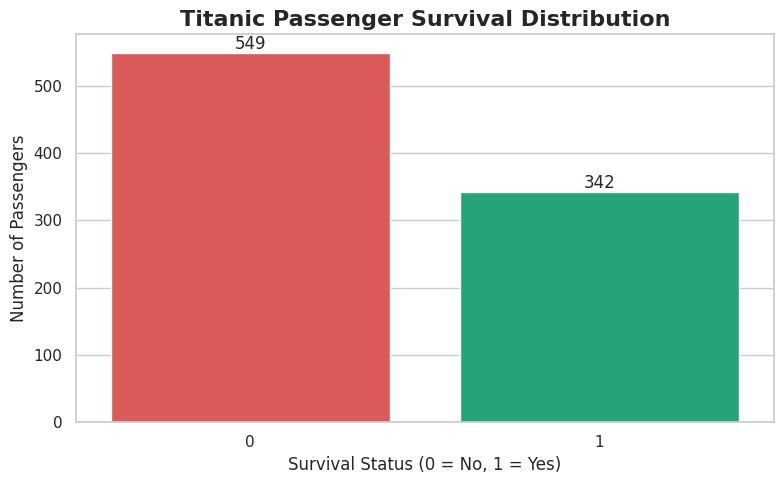

In [10]:

# SURVIVAL DISTRIBUTION

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Survived",
    hue="Survived",
    palette={0: "#EF4444", 1: "#10B981"},
    legend=False,
    ax=ax
)

ax.set_title(
    "Titanic Passenger Survival Distribution",
    fontsize=16,
    fontweight="bold"
)
ax.set_xlabel("Survival Status (0 = No, 1 = Yes)")
ax.set_ylabel("Number of Passengers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

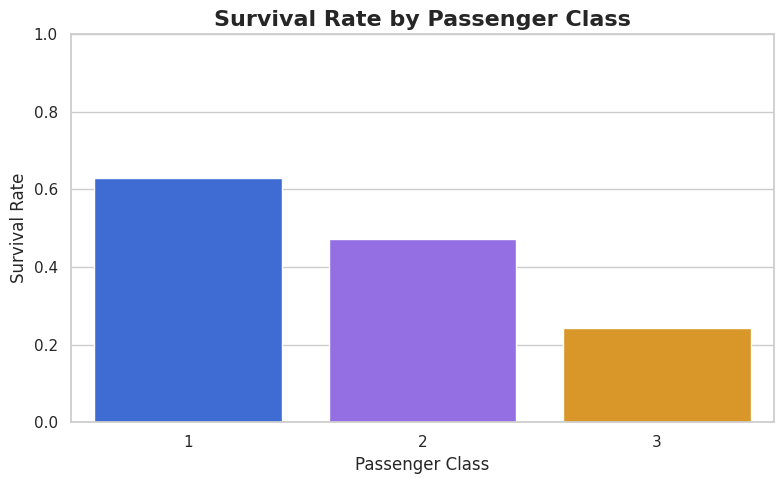

In [11]:

#  SURVIVAL BY PASSENGER CLASS

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Pclass",
    y="Survived",
    hue="Pclass",
    palette=["#2563EB", "#8B5CF6", "#F59E0B"],
    legend=False,
    errorbar=None,
    ax=ax
)

ax.set_title(
    "Survival Rate by Passenger Class",
    fontsize=16,
    fontweight="bold"
)
ax.set_xlabel("Passenger Class")
ax.set_ylabel("Survival Rate")

ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

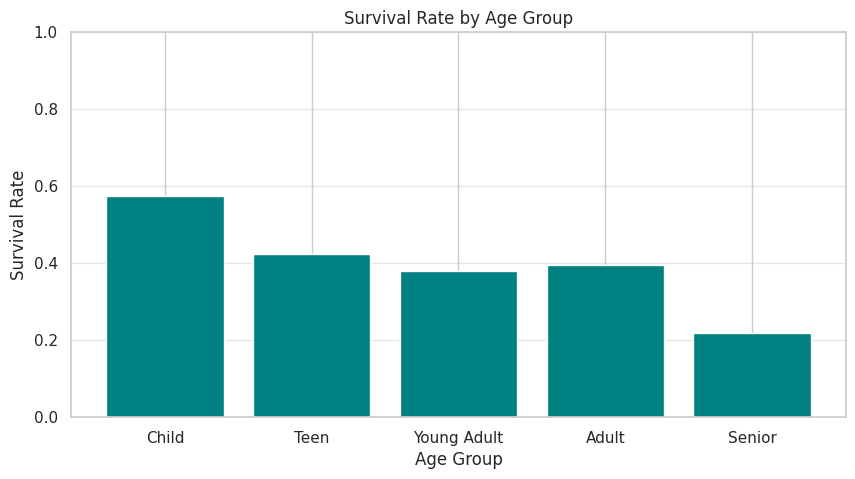

In [26]:
%matplotlib inline
import matplotlib.pyplot as plt

age_groups = ["Child", "Teen", "Young Adult", "Adult", "Senior"]
survival_rates = [0.575, 0.425, 0.38, 0.395, 0.22]

plt.figure(figsize=(10, 5))
plt.bar(age_groups, survival_rates, color="teal")
plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.5)
plt.show()

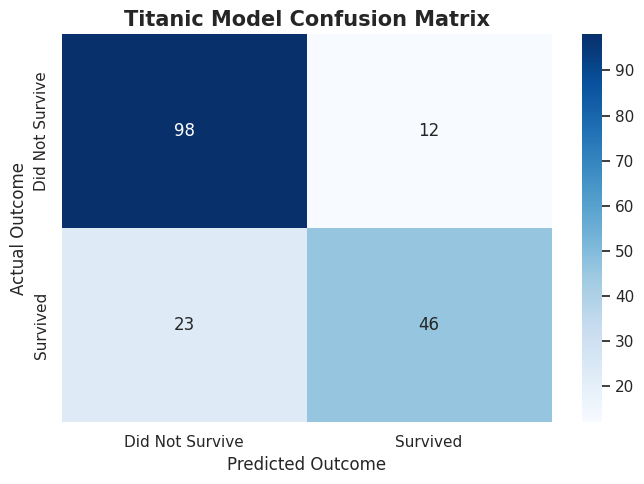

                 precision    recall  f1-score   support

Did Not Survive       0.81      0.89      0.85       110
       Survived       0.79      0.67      0.72        69

       accuracy                           0.80       179
      macro avg       0.80      0.78      0.79       179
   weighted avg       0.80      0.80      0.80       179



In [12]:

#  MODEL CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Did Not Survive", "Survived"],
    yticklabels=["Did Not Survive", "Survived"],
    ax=ax
)

ax.set_title("Titanic Model Confusion Matrix",
             fontsize=15, fontweight="bold")
ax.set_xlabel("Predicted Outcome")
ax.set_ylabel("Actual Outcome")

plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_pred,
    target_names=["Did Not Survive", "Survived"]
))

In [13]:

# INFOZATECH TASK 5
# TITANIC SURVIVAL PREDICTION DASHBOARD

import gradio as gr
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

from sklearn.metrics import confusion_matrix

# ---------------------------------
# 1. DASHBOARD CHARTS
# ---------------------------------

def survival_distribution():
    fig, ax = plt.subplots(figsize=(7, 4))

    sns.countplot(
        data=df,
        x="Survived",
        hue="Survived",
        palette={0: "#EF4444", 1: "#10B981"},
        legend=False,
        ax=ax
    )

    ax.set_xticks([0, 1], ["Did Not Survive", "Survived"])
    ax.set_title("Passenger Survival Distribution",
                 fontsize=14, fontweight="bold")
    ax.set_xlabel("Survival Status")
    ax.set_ylabel("Number of Passengers")

    for container in ax.containers:
        ax.bar_label(container)

    fig.tight_layout()
    return fig


def class_survival_chart():
    fig, ax = plt.subplots(figsize=(7, 4))

    sns.barplot(
        data=df,
        x="Pclass",
        y="Survived",
        hue="Pclass",
        palette=["#2563EB", "#8B5CF6", "#F59E0B"],
        legend=False,
        errorbar=None,
        ax=ax
    )

    ax.set_title("Survival Rate by Passenger Class",
                 fontsize=14, fontweight="bold")
    ax.set_xlabel("Passenger Class")
    ax.set_ylabel("Survival Rate")
    ax.set_ylim(0, 1)

    fig.tight_layout()
    return fig


def age_survival_chart():
    chart_df = df.copy()
    chart_df["Age Group"] = pd.cut(
        chart_df["Age"],
        bins=[0, 12, 18, 35, 60, 100],
        labels=["Child", "Teen", "Young Adult", "Adult", "Senior"]
    )

    fig, ax = plt.subplots(figsize=(8, 4))

    sns.barplot(
        data=chart_df,
        x="Age Group",
        y="Survived",
        color="#0D9488",
        errorbar=None,
        ax=ax
    )

    ax.set_title("Survival Rate by Age Group",
                 fontsize=14, fontweight="bold")
    ax.set_xlabel("Age Group")
    ax.set_ylabel("Survival Rate")
    ax.set_ylim(0, 1)

    fig.tight_layout()
    return fig


def confusion_matrix_chart():
    fig, ax = plt.subplots(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Did Not Survive", "Survived"],
        yticklabels=["Did Not Survive", "Survived"],
        ax=ax
    )

    ax.set_title("Model Confusion Matrix",
                 fontsize=14, fontweight="bold")
    ax.set_xlabel("Predicted Outcome")
    ax.set_ylabel("Actual Outcome")

    fig.tight_layout()
    return fig


# ---------------------------------
# 2. PASSENGER PREDICTION
# ---------------------------------

def predict_survival(
    pclass, sex, age, sibsp, parch, fare, embarked
):
    passenger = pd.DataFrame([{
        "Pclass": int(pclass),
        "Sex": sex,
        "Age": float(age),
        "SibSp": int(sibsp),
        "Parch": int(parch),
        "Fare": float(fare),
        "Embarked": embarked
    }])

    prediction = int(titanic_model.predict(passenger)[0])
    probabilities = titanic_model.predict_proba(passenger)[0]

    probability_dict = {
        "Did Not Survive": float(probabilities[0]),
        "Survived": float(probabilities[1])
    }

    result = (
        "🟢 Prediction: Survived"
        if prediction == 1
        else "🔴 Prediction: Did Not Survive"
    )

    return result, probability_dict


# ---------------------------------
# 3. DASHBOARD DESIGN
# ---------------------------------

custom_css = """
.gradio-container {
    background: #F1F5F9 !important;
}
#main-header {
    background: linear-gradient(135deg, #102A43, #2563EB);
    color: white;
    padding: 24px;
    border-radius: 16px;
    text-align: center;
}
"""

with gr.Blocks(
    title="InfozaTech Titanic Survival Dashboard"
) as demo:

    gr.HTML("""
    <div id="main-header">
        <h1>🚢 Titanic Survival Prediction</h1>
        <p>INFOZATECH | Data Science Internship — Task 5</p>
        <p>Passenger Analytics & Machine Learning</p>
    </div>
    """)

    gr.Markdown("## 📊 Dashboard Overview")

    with gr.Row():
        gr.Number(
            value=len(df),
            label="Passenger Records",
            interactive=False
        )
        gr.Number(
            value=int(df["Survived"].sum()),
            label="Survivors in Dataset",
            interactive=False
        )
        gr.Number(
            value=round(accuracy * 100, 2),
            label="Model Accuracy (%)",
            interactive=False
        )
        gr.Number(
            value=round(f1, 3),
            label="F1 Score",
            interactive=False
        )

    with gr.Tabs():

        with gr.Tab("📁 Dataset"):
            gr.Markdown("### Titanic Dataset Preview")
            gr.Dataframe(
                value=df.head(10),
                interactive=False
            )

            gr.Markdown("### Survival Counts")
            gr.Dataframe(
                value=df["Survived"].value_counts()
                    .sort_index()
                    .rename(index={
                        0: "Did Not Survive",
                        1: "Survived"
                    })
                    .rename_axis("Outcome")
                    .reset_index(name="Passengers"),
                interactive=False
            )

        with gr.Tab("📈 Visualizations"):
            gr.Markdown("### Explore Passenger Survival")

            gr.Plot(value=survival_distribution)
            gr.Plot(value=class_survival_chart)
            gr.Plot(value=age_survival_chart)

        with gr.Tab("🤖 Model Performance"):
            gr.Markdown("### Logistic Regression Evaluation")

            gr.Dataframe(
                value=pd.DataFrame({
                    "Metric": [
                        "Accuracy", "Precision",
                        "Recall", "F1 Score"
                    ],
                    "Value": [
                        accuracy, precision, recall, f1
                    ]
                }).round(4),
                interactive=False
            )

            gr.Plot(value=confusion_matrix_chart)

        with gr.Tab("🔮 Predict Survival"):
            gr.Markdown("""
            ### Enter Passenger Details
            Adjust the values and click **Predict Survival**.
            The model will estimate the passenger's survival outcome.
            This is a model prediction, not a historical fact.
            """)

            pclass = gr.Slider(
                minimum=1, maximum=3, value=3,
                step=1, label="Passenger Class"
            )

            sex = gr.Radio(
                choices=["female", "male"],
                value="female",
                label="Sex"
            )

            age = gr.Slider(
                minimum=0.5, maximum=80, value=25,
                step=0.5, label="Age"
            )

            sibsp = gr.Slider(
                minimum=0, maximum=8, value=0,
                step=1, label="Siblings / Spouses Aboard"
            )

            parch = gr.Slider(
                minimum=0, maximum=6, value=0,
                step=1, label="Parents / Children Aboard"
            )

            fare = gr.Slider(
                minimum=0, maximum=513, value=32,
                step=1, label="Ticket Fare"
            )

            embarked = gr.Radio(
                choices=["S", "C", "Q"],
                value="S",
                label="Port of Embarkation"
            )

            predict_button = gr.Button(
                "🔮 Predict Survival",
                variant="primary"
            )

            result = gr.Textbox(
                label="Predicted Outcome"
            )

            probabilities = gr.Label(
                label="Prediction Probabilities",
                num_top_classes=2
            )

            predict_button.click(
                fn=predict_survival,
                inputs=[
                    pclass, sex, age, sibsp,
                    parch, fare, embarked
                ],
                outputs=[result, probabilities]
            )

    gr.Markdown("""
    ---
    **Project Conclusion:** This project uses passenger data,
    exploratory visualizations, and Logistic Regression to estimate
    Titanic survival outcomes.

    *Developed for the InfozaTech Data Science Internship.*
    """)

demo.launch(
    share=True,
    theme=gr.themes.Soft(
        primary_hue="blue",
        secondary_hue="cyan"
    ),
    css=custom_css
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7f0fd7d6f1a49368fa.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# Task 5: Titanic Survival Prediction

## Objective

The objective of this project is to analyze passenger data from the Titanic disaster and predict passenger survival using machine learning techniques.

## Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Google Colab / Jupyter Notebook
- GitHub

## Project Implementation

1. Loaded and explored the Titanic passenger dataset.
2. Examined dataset information, descriptive statistics, and missing values.
3. Cleaned and preprocessed the data for analysis and model training.
4. Performed exploratory data analysis to identify patterns in passenger survival.
5. Visualized survival rates based on passenger features, including age groups.
6. Analyzed relationships between passenger characteristics and survival outcomes.
7. Prepared features and target variables for machine learning.
8. Trained a classification model to predict passenger survival.
9. Evaluated model performance using accuracy and a confusion matrix.
10. Visualized important findings to communicate survival patterns and model results.

## Outcome

Developed a Titanic Survival Prediction project combining data preprocessing, exploratory data analysis, data visualization, and machine learning classification to predict passenger survival.

## Conclusion

This project provided practical experience in data cleaning, exploratory data analysis, visualization, classification modelling, and model evaluation using Python. It demonstrated how machine learning can be applied to historical passenger data to explore survival patterns and make predictions.

**Project:** InfozaTech Data Science Internship — Task 5